# GPT-2 recipes: full fine-tuning and LoRA

**Utkrisht Suman · A24ARIU0001**

Executed on Google Colab with a Tesla T4, PyTorch 2.14.1+cu130 and Transformers 5.22.1. Both experiments used seed 42, the full eligible training split, two epochs and batch size 8. The recorded outputs below are from that run; the written answers summarize those outputs. The optional Llama extension was not run.

The task is to generate a recipe method from the dish metadata and ingredients, and compare original GPT-2, full fine-tuning and a rank-8 attention LoRA adapter. Source scaffold: the course gpt2_lora_recipes_lab.ipynb by bk-anupam, generative_ai_shared. Dataset attribution and responsible-use notes are retained below.

## Setup

**Installation (Kaggle).** Run the next cell once per session.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.

In [2]:
# Run this first in a fresh Kaggle session with Internet ON.
from pathlib import Path
import sys, subprocess, re
from importlib import metadata
if Path('/kaggle/working').exists():
    keep_torch = Path('/kaggle/working/keep_cuda_torch.txt')
    keep_torch.write_text('torch==' + metadata.version('torch') + '\n')
    packages = ['transformers==5.22.2', 'peft==0.21.2', 'accelerate==1.15.0', 'datasets==5.1.0', 'sacrebleu==2.6.0', 'rouge_score==0.1.2']
    def installed(name):
        try: return metadata.version(name)
        except metadata.PackageNotFoundError: return None
    names=[re.split(r'[<>=!~]', spec, maxsplit=1)[0] for spec in packages]
    before={name: installed(name) for name in names}
    already_loaded = any(name in sys.modules for name in ['transformers','peft','datasets','accelerate'])
    subprocess.run([sys.executable,'-m','pip','install','-q','-c',str(keep_torch),*packages],check=True)
    changed=any(before[name] != installed(name) for name in names)
    if already_loaded and changed:
        raise RuntimeError('Dependencies installed. Restart the notebook kernel/session, then Run All from the top.')
    print('Dependencies ready; Kaggle CUDA torch preserved.')
else:
    print('Local run: install requirements.txt first.')


Local run: install requirements.txt first.


In [3]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import hashlib
import math
import random
import re
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "openai-community/gpt2"
MAX_LEN = 768            # longest training example in tokens; longer ones are dropped, not truncated
MAX_NEW = 400            # longest generated method, in tokens
N_EVAL = 40              # validation recipes for BLEU/ROUGE and reading
EPOCHS = 2
BATCH = 8
TRAIN_LIMIT = None       # e.g. 200 for a quick smoke run; None for the real run
OUT = Path("/kaggle/working/recipe_lab") if Path("/kaggle/working").is_dir() else Path("recipe_lab_outputs")
DATA_DIR, ADAPTER_DIR = OUT / "data", OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-3 only)")
ALLOW_CPU = False  # Set True only if intentionally accepting a very slow CPU run.


torch 2.14.1+cu130 | transformers 5.22.1
GPU: Tesla T4


## The data

The next cell downloads the dataset's CSV file (24 MB) from Mendeley Data, once, and checks its SHA-256 hash, so everyone works with the same file. If your environment has no internet, download `IndianFoodDatasetCSV.csv` from the [dataset page](https://data.mendeley.com/datasets/xsphgmmh7b/1) and put it in the `data/` folder printed below.

In [4]:
DATA_URL = ("https://data.mendeley.com/public-files/datasets/xsphgmmh7b/files/"
            "6fb5ae32-a815-4b8f-9d68-8d512227eac8/file_downloaded")
DATA_SHA256 = "273f8d45f41aca9af0396dda07af137c68c7387a1506992904144b944c4346be"
csv_path = DATA_DIR / "IndianFoodDatasetCSV.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not csv_path.exists():
    print("downloading to", csv_path)
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "recipe-lab"})   # the default agent gets 403
    with urllib.request.urlopen(request) as response:
        csv_path.write_bytes(response.read())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == DATA_SHA256, "unexpected file: delete it and download again"

raw = pd.read_csv(csv_path, encoding="utf-8-sig")
raw = raw.apply(lambda col: col if pd.api.types.is_numeric_dtype(col) else col.str.replace("\ufeff", "").str.strip())
print(raw.shape)
print(raw.columns.tolist())
raw.iloc[0][["RecipeName", "Cuisine", "Course", "Diet", "Ingredients", "Instructions"]].to_dict()

downloading to recipe_lab_outputs/data/IndianFoodDatasetCSV.csv
(6871, 15)
['Srno', 'RecipeName', 'TranslatedRecipeName', 'Ingredients', 'TranslatedIngredients', 'PrepTimeInMins', 'CookTimeInMins', 'TotalTimeInMins', 'Servings', 'Cuisine', 'Course', 'Diet', 'Instructions', 'TranslatedInstructions', 'URL']


{'RecipeName': 'Masala Karela Recipe',
 'Cuisine': 'Indian',
 'Course': 'Side Dish',
 'Diet': 'Diabetic Friendly',
 'Ingredients': '6 Karela (Bitter Gourd/ Pavakkai) - deseeded,Salt - to taste,1 Onion - thinly sliced,3 tablespoon Gram flour (besan),2 teaspoons Turmeric powder (Haldi),1 tablespoon Red Chilli powder,2 teaspoons Cumin seeds (Jeera),1 tablespoon Coriander Powder (Dhania),1 tablespoon Amchur (Dry Mango Powder),Sunflower Oil - as required',
 'Instructions': 'To begin making the\xa0Masala Karela Recipe,de-seed the karela and slice. Do not remove the skin as the skin has all the nutrients.\xa0Add the karela to the pressure cooker with 3 tablespoon of water, salt and turmeric powder and pressure cook for three whistles. Release the pressure immediately and open the lids. Keep aside.Heat oil in a heavy bottomed pan or a kadhai. Add cumin seeds and let it sizzle.Once the cumin seeds have sizzled, add onions and saute them till it turns golden brown in color.Add the karela,\xa0red

**Reading the output.** Each row is one web page of the recipe site. `Ingredients` is one comma-separated string; `Instructions` is the method as one paragraph. About a fifth of the pages are in Hindi; for those, the `Translated…` columns hold a machine translation (made with Google Translate by the dataset's author). Several dishes appear twice: once in English and once as "(Recipe In Hindi)".

The next cell applies three filters. They are given, not part of an exercise, but read them: each is a data decision you should be able to justify.

1. **English originals only.** Drop rows whose original name, ingredients, or method contain Devanagari script. This removes the Hindi pages and their machine translations, which are of uneven quality and are often a second copy of an English recipe.
2. **Indian cuisines only.** The site also publishes Continental, Italian, Chinese, Mexican and other recipes, and a few rows have a course ("Snack", "Dinner") in the cuisine field. Drop those.
3. **Cleaning.** Add the missing space in run-together sentences ("Keep aside.Heat oil"), remove the word "Recipe" from dish names, and split the ingredient string into a list.

In [5]:
DEVANAGARI = r"[\u0900-\u097F]"
NOT_INDIAN = {"Afghan", "African", "American", "Arab", "Asian", "British", "Burmese", "Cantonese", "Caribbean",
              "Chinese", "Continental", "European", "French", "Fusion", "Greek", "Hunan", "Indonesian",
              "Italian Recipes", "Japanese", "Jewish", "Korean", "Malaysian", "Mediterranean", "Mexican",
              "Middle Eastern", "Nepalese", "Pakistani", "Shandong", "Sichuan", "Sri Lankan", "Thai",
              "Vietnamese", "World Breakfast",
              "Appetizer", "Brunch", "Dessert", "Dinner", "Lunch", "Side Dish", "Snack"}   # courses, not cuisines


def clean_text(t):
    t = re.sub(r"\.(?=[A-Z])", ". ", t)        # "aside.Heat" -> "aside. Heat"
    t = re.sub(r",(?=[A-Za-z])", ", ", t)       # "Recipe,de-seed" -> "Recipe, de-seed"
    return " ".join(t.split())


def clean_name(name):
    return " ".join(re.sub(r"\brecipe\b", "", name, flags=re.IGNORECASE).split()).strip(" -")


english = ~(raw["RecipeName"].str.contains(DEVANAGARI) | raw["Ingredients"].fillna("").str.contains(DEVANAGARI)
            | raw["Instructions"].str.contains(DEVANAGARI))
kept = raw[english & raw["Ingredients"].notna() & ~raw["Cuisine"].isin(NOT_INDIAN)]
recipes = [{"raw_name": r.RecipeName, "name": clean_name(r.RecipeName), "cuisine": r.Cuisine,
            "course": r.Course, "diet": r.Diet,
            "ingredients": [i.strip() for i in r.Ingredients.split(",") if i.strip()],
            "method": clean_text(r.Instructions)} for r in kept.itertuples()]
print(f"{len(raw):,} rows -> {english.sum():,} English originals -> {len(recipes):,} Indian recipes")
print(kept["Cuisine"].value_counts().head(8).to_string())

6,871 rows -> 5,659 English originals -> 3,708 Indian recipes
Cuisine
Indian                   870
North Indian Recipes     688
South Indian Recipes     503
Maharashtrian Recipes    144
Bengali Recipes          140
Karnataka                132
Kerala Recipes           126
Tamil Nadu               124


## Exercise 1 — Split by dish, not by row (3 marks)

The site often has two pages for one dish: "Aamras Recipe" and "Aamras Recipe - Ripe Mango Ras", or the same name published twice. Their methods share many phrases. If one copy lands in training and the other in validation, the fine-tuned model can score well on validation by **remembering** a recipe it was trained on, which inflates BLEU and ROUGE. (This is the leakage problem from the data-preparation lecture.)

The fix is a **group split**: give every recipe a *dish key*, and put all recipes with the same key in the same split.

Complete `dish_key(raw_name)`:

1. Lowercase the name.
2. Keep only the part before the first `" - "` or `"("`.
3. Remove the word `recipe` (or `recipes`) as a whole word.
4. Replace every character that is not a letter `a`–`z` or a space with a space, and collapse repeated spaces (strip both ends).

In [6]:
def dish_key(raw_name):
    name = re.split(r" - |\(", str(raw_name).lower(), maxsplit=1)[0]
    name = re.sub(r"\brecipes?\b", " ", name)
    return " ".join(re.sub(r"[^a-z ]", " ", name).split())

In [7]:
assert dish_key("Aamras Recipe - Ripe Mango Ras") == dish_key("Aamras Recipe") == "aamras"
assert dish_key("Achari Paneer Masala Recipe") == "achari paneer masala"
assert dish_key("Bengali Doi Maach Recipe (Fish In Yogurt Curry)") == "bengali doi maach"
for r in recipes:
    r["key"] = dish_key(r["raw_name"])

# Group split: shuffle the distinct keys, then 80% / 10% / 10% of the keys -> train / validation / test
keys = sorted({r["key"] for r in recipes})
random.Random(SEED).shuffle(keys)
n_val = n_test = len(keys) // 10
split_of = {k: "val" for k in keys[:n_val]} | {k: "test" for k in keys[n_val:n_val + n_test]} \
         | {k: "train" for k in keys[n_val + n_test:]}
splits = {s: [r for r in recipes if split_of[r["key"]] == s] for s in ("train", "val", "test")}
assert not ({r["key"] for r in splits["train"]} & {r["key"] for r in splits["val"] + splits["test"]})
print({s: len(rs) for s, rs in splits.items()}, f"| {len(keys):,} distinct dishes")

# What a random *row* split would have done
shuffled = random.Random(SEED).sample(recipes, len(recipes))
row_val, row_train = shuffled[:len(recipes) // 10], shuffled[len(recipes) // 10:]
train_keys = {r["key"] for r in row_train}
twins = [r for r in row_val if r["key"] in train_keys]
print(f"random row split: {len(twins)} of {len(row_val)} validation recipes have a same-dish twin in training")
for r in twins[:3]:
    print("  ", r["raw_name"], "<->", next(t["raw_name"] for t in row_train if t["key"] == r["key"]))
print("Exercise 1 checks passed.")

{'train': 2970, 'val': 369, 'test': 369} | 3,694 distinct dishes
random row split: 6 of 370 validation recipes have a same-dish twin in training
   Badam Halwa Recipe - Delicious Almond Halwa With Khoya <-> Badam Halwa Recipe
   Jal Jeera Recipe - Sweet And Sour Cumin Water Recipe <-> Jal Jeera Recipe - Indian Spiced Lemonade
   Muttaikose Poriyal Recipe -  Purple Cabbage Poriyal | Red Cabbage Sabzi <-> Muttaikose Poriyal Recipe - Cabbage Stir fry With Coconut
Exercise 1 checks passed.


**Question 1.** (a) Use the printed numbers: how many validation recipes would a random row split have leaked, and why does even a small number matter for BLEU/ROUGE? (b) Give one pair of recipes that `dish_key` would **not** group although they are really the same dish, and one pair it groups although they are different. Is the key too strict or too loose? (c) The test split is created but never used in this lab. Why keep it?

**Answer 1 - measured split.** A random row split leaked same-dish training twins for 6 of 370 validation recipes (about 1.62%). The grouped split instead has 2,970 training, 369 validation and 369 test recipes across 3,694 distinct dish keys, with no key shared between partitions. The key is a heuristic: aliases such as chole and chana masala may remain separate, while stripping a suffix can merge different preparations such as dal - dry and dal - curry. The printed Badam Halwa examples show why closely related recipe variants should be held together. I would inspect frequent keys and aliases before a larger study; the test partition stays untouched for selection.

## The prompt format

Every example is a **prompt** (what the model is given) followed by the **method** (what it should write). GPT-2 is a plain language model, not a chat model, so the prompt is plain text with field labels. The same format is used for training, for the original model, and for the fine-tuned models.

In [8]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CKPT)     # a few MB; the model is downloaded in Exercise 4
tokenizer.pad_token = tokenizer.eos_token           # GPT-2 has no pad token; padding is masked anyway


def format_prompt(r):
    ingredients = "\n".join(f"- {i}" for i in r["ingredients"])
    return (f"Dish: {r['name']}\nCuisine: {r['cuisine']} | Course: {r['course']} | Diet: {r['diet']}\n"
            f"Ingredients:\n{ingredients}\nMethod:\n")


def prompt_ids(r, tok, add_bos):
    """Token IDs of the prompt. GPT-2 uses no beginning-of-text token; Llama does (see the extension)."""
    ids = tok(format_prompt(r), add_special_tokens=False)["input_ids"]
    return ([tok.bos_token_id] if add_bos else []) + ids


r0 = splits["train"][0]
print(format_prompt(r0) + r0["method"][:300] + " …")
print("\nend-of-text token:", repr(tokenizer.eos_token), tokenizer.eos_token_id)
for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
    print(f"{word:>8} -> {tokenizer.tokenize(' ' + word)}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Dish: Ragi Semiya Upma - Ragi Millet Vermicelli Breakfast
Cuisine: South Indian Recipes | Course: South Indian Breakfast | Diet: High Protein Vegetarian
Ingredients:
- 1-1/2 cups Rice Vermicelli Noodles (Thin)
- 1 Onion - sliced
- 1/2 cup Carrots (Gajjar) - chopped
- 1/3 cup Green peas (Matar)
- 2 Green Chillies
- 1/4 teaspoon Asafoetida (hing)
- 1 teaspoon Mustard seeds
- 1 teaspoon White Urad Dal (Split)
- 1 teaspoon Ghee
- 1 sprig Curry leaves
- Salt - to taste
- 1 teaspoon Lemon juice
Method:
To begin making the Ragi Vermicelli Recipe, first steam the ragi vermicelli in a rice cooker or a steamer for about 5-6 minutes or till it is cooked but firm. Keep aside this aside till later use. You can add a few drops of oil and mix it so that they don't stick to each other. Place a kadai on the  …

end-of-text token: '<|endoftext|>' 50256
  potato -> ['Ġpotato']
   cumin -> ['Ġc', 'umin']
  karela -> ['Ġk', 'are', 'la']
  amchur -> ['Ġam', 'ch', 'ur']
  kadhai -> ['Ġk', 'adh', 'ai']
   tad

The last lines show how GPT-2's byte-pair encoding splits words. Common English words are one token; Indian ingredient and utensil names, rare in GPT-2's training text, are split into several pieces. Every extra piece costs context length and is one more prediction the model can get wrong.

## Exercise 2 — Training examples with a masked prompt (4 marks)

As in the [GPT-2 fine-tuning notebook](../../lectures/fine_tuning/gpt2_fine_tuning.ipynb), we want the loss to cover **only the method**, and the method must end with the end-of-text token so that the model learns to stop. Positions whose label is **−100** are ignored by the loss, and the model shifts the labels by one position internally.

Complete `build_example(r, tok, add_bos)`:

1. `p` = `prompt_ids(r, tok, add_bos)`.
2. `a` = the tokens of `r["method"]` (with `add_special_tokens=False`), followed by `tok.eos_token_id`.
3. `input_ids` = `p + a`; `attention_mask` = all ones; `labels` = −100 for every prompt position, followed by `a`.

Return a dict of plain Python lists under `input_ids`, `attention_mask`, and `labels`. The function takes the tokenizer as an argument so that the Llama extension can reuse it.

In [9]:
def build_example(r, tok, add_bos):
    prompt = prompt_ids(r, tok, add_bos)
    answer = tok(r["method"], add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    ids = prompt + answer
    return {"input_ids": ids, "attention_mask": [1] * len(ids),
            "labels": [-100] * len(prompt) + answer}

In [10]:
ex = build_example(r0, tokenizer, add_bos=False)
n_prompt = len(prompt_ids(r0, tokenizer, add_bos=False))
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "method labels must equal the method tokens"
assert ex["input_ids"][-1] == tokenizer.eos_token_id, "the method must end with the end-of-text token"
assert tokenizer.decode(ex["input_ids"][:n_prompt], clean_up_tokenization_spaces=False) == format_prompt(r0)
print(f"{len(ex['input_ids'])} tokens, {len(ex['input_ids']) - n_prompt} of them scored")
print("scored text ends with:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])[-80:]))


def make_dataset(rows, tok, add_bos):
    data = [build_example(r, tok, add_bos) for r in rows]
    return [e for e in data if len(e["input_ids"]) <= MAX_LEN]


train_rows = splits["train"][:TRAIN_LIMIT]
train_data = make_dataset(train_rows, tokenizer, add_bos=False)
val_data = make_dataset(splits["val"], tokenizer, add_bos=False)
eval_rows = random.Random(SEED).sample(splits["val"], N_EVAL)     # for generation and BLEU/ROUGE
lengths = sorted(len(build_example(r, tokenizer, False)["input_ids"]) for r in train_rows)
print(f"training examples: {len(train_data):,} kept of {len(train_rows):,} (> {MAX_LEN} tokens dropped)"
      f" | validation examples: {len(val_data)}")
print(f"tokens per example: median {lengths[len(lengths) // 2]}, 90th percentile {lengths[int(0.9 * len(lengths))]}, "
      f"max {lengths[-1]}")
print("Exercise 2 checks passed.")

423 tokens, 261 of them scored
scored text ends with: 't Chutney and a hot cup of coffee or tea for a wholesome breakfast.<|endoftext|>'
training examples: 2,862 kept of 2,970 (> 768 tokens dropped) | validation examples: 359
tokens per example: median 430, 90th percentile 636, max 1337
Exercise 2 checks passed.


**Question 2.** (a) Why is the prompt masked? Which part of the prompt would the model waste effort learning if it were not? (b) What does the end-of-text token at the end of the labels teach the model? What would you expect to see at generation time without it? (c) Why drop examples longer than `MAX_LEN` instead of truncating them? Use the printed length statistics to say how many examples this costs.

**Answer 2 - measured preprocessing.** Of 2,970 grouped training recipes, 2,862 were retained and 108 exceeded 768 tokens. There are 359 retained validation examples. Median training-example length was 430 tokens, the 90th percentile 636 and the maximum 1,337. Prompt labels are -100 so only the method and EOS are learned. EOS remains supervised even though it is also used for padding. Dropping long examples preserves complete methods but favours shorter recipes.

## Exercise 3 — BLEU and ROUGE (3 marks)

Both metrics compare a generated text, the **candidate**, with a human-written **reference** by counting shared words and word sequences (*n-grams*). Neither looks at meaning.

**BLEU** (Papineni et al., 2002), recapped from Module 2: for n = 1 to 4, the **clipped n-gram precision** $p_n$ is the fraction of the candidate's n-grams that also occur in the reference, where each reference n-gram can be matched at most as many times as it occurs there. BLEU is the geometric mean of $p_1 \dots p_4$ times a **brevity penalty** $\mathrm{BP} = \min(1, e^{1 - r/c})$, where $c$ is the candidate length and $r$ the reference length. Precision rewards saying only what the reference says; BP stops a short candidate from winning by saying very little. **Corpus BLEU** adds up the n-gram counts over all candidates before dividing, so it is not the average of per-sentence BLEU scores. We use `sacrebleu`, which fixes the tokenization so that scores are comparable (Post, 2018), and report BLEU on a 0–100 scale.

**ROUGE** (Lin, 2004) was designed for summaries, where the question is how much of the reference the candidate **recovers**:

- **ROUGE-1** and **ROUGE-2** count overlapping unigrams and bigrams. Recall = overlap / reference n-grams; precision = overlap / candidate n-grams; we report their harmonic mean, **F1**.
- **ROUGE-L** uses the **longest common subsequence** (LCS): the longest sequence of words that appears in both texts in the same order, not necessarily next to each other. Recall = LCS / reference length, precision = LCS / candidate length, then F1.

We use Google's `rouge_score` package with stemming, and average F1 over the recipes (× 100).

**(a) By hand.** Candidate: *heat oil in a pan*. Reference: *heat the oil in a kadhai*. Compute ROUGE-1 precision, recall, and F1; ROUGE-2 F1; the LCS and ROUGE-L F1; and BLEU's brevity penalty for this pair. Write your working in the answer cell below; the check cell compares your F1 values with the library's.

**(b) Code.** Complete `text_metrics(preds, refs)`. It returns a dict with `"BLEU"` (corpus BLEU from `sacrebleu.corpus_bleu(preds, [refs]).score`) and `"ROUGE-1"`, `"ROUGE-2"`, `"ROUGE-L"` (mean F1 × 100, using `scorer.score(reference, prediction)`: **reference first**).

**Answer 3(a).** The candidate has 5 words and the reference 6. Four unigrams match: heat, oil, in, a. Precision is 4/5 and recall 4/6, giving ROUGE-1 F1 = 8/11 = 0.7273. The matching bigrams are “oil in” and “in a”: precision 2/4 and recall 2/5, so ROUGE-2 F1 = 4/9 = 0.4444. The longest common subsequence has length 4, so ROUGE-L F1 is also 8/11. BLEU's brevity penalty is exp(1 - 6/5) = 0.8187. These are overlap scores; they do not establish whether cooking instructions are safe or complete.

In [1]:
import sys
import subprocess

# Automatically install sacrebleu and rouge_score if they are not already installed
try:
    import sacrebleu
    from rouge_score import rouge_scorer
except ImportError:
    print("Installing missing dependencies: sacrebleu, rouge_score...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu==2.6.0", "rouge_score==0.1.2"], check=True)
    import sacrebleu
    from rouge_score import rouge_scorer

ROUGE_KEYS = {"ROUGE-1": "rouge1", "ROUGE-2": "rouge2", "ROUGE-L": "rougeL"}
scorer = rouge_scorer.RougeScorer(list(ROUGE_KEYS.values()), use_stemmer=True)

def text_metrics(preds, refs):
    if not preds or len(preds) != len(refs):
        raise ValueError("Provide the same nonzero number of predictions and references")
    scores = [scorer.score(ref, pred) for ref, pred in zip(refs, preds)]
    result = {"BLEU": sacrebleu.corpus_bleu(preds, [refs]).score}
    result.update({label: 100 * sum(s[key].fmeasure for s in scores) / len(scores)
                   for label, key in ROUGE_KEYS.items()})
    return result

Installing missing dependencies: sacrebleu, rouge_score...


In [11]:
m = text_metrics(["heat oil in a pan"], ["heat the oil in a kadhai"])
print({k: round(v, 1) for k, v in m.items()})
assert abs(m["ROUGE-1"] - 72.7) < 0.1 and abs(m["ROUGE-2"] - 44.4) < 0.1 and abs(m["ROUGE-L"] - 72.7) < 0.1
assert abs(text_metrics(["add salt and stir well"], ["add salt and stir well"])["BLEU"] - 100) < 1e-6
print("Exercise 3 checks passed.")

{'BLEU': 35.0, 'ROUGE-1': 72.7, 'ROUGE-2': 44.4, 'ROUGE-L': 72.7}
Exercise 3 checks passed.


BLEU and ROUGE only count words. They cannot tell whether a method actually uses the ingredients it was given, so we add one task-specific check. `ingredient_coverage` reduces each listed ingredient to its last word ("Red Chilli powder" → *powder*, "Sunflower Oil - as required" → *oil*) and reports the fraction of these words that appear in the method. It is deliberately crude: it misses synonyms (*besan* vs. *gram flour*) and cannot tell *using* an ingredient from *mentioning* it. We apply it to the human-written references too, which gives a realistic upper range.

In [12]:
UNITS = r"\b(cups?|tablespoons?|teaspoons?|tbsp|tsp|grams?|gms?|g|kg|ml|litres?|liters?|inch|pinch|sprigs?|cloves?|pieces?|nos?)\b"


def ingredient_words(ingredients):
    words = set()
    for item in ingredients:
        name = re.split(r" - |\(", item.lower())[0]
        name = re.sub(UNITS, " ", re.sub(r"[^a-z ]", " ", name))
        if name.split():
            words.add(name.split()[-1])
    return words


def ingredient_coverage(rows, methods):
    fractions = []
    for r, m in zip(rows, methods):
        words, text = ingredient_words(r["ingredients"]), set(re.findall(r"[a-z]+", m.lower()))
        fractions.append(len(words & text) / max(len(words), 1))
    return 100 * sum(fractions) / len(fractions)


print(sorted(ingredient_words(r0["ingredients"])))
print(f"reference methods mention {ingredient_coverage(eval_rows, [r['method'] for r in eval_rows]):.0f}% "
      "of their ingredient words (validation sample)")

['asafoetida', 'carrots', 'chillies', 'dal', 'ghee', 'juice', 'leaves', 'noodles', 'onion', 'peas', 'salt', 'seeds']
reference methods mention 77% of their ingredient words (validation sample)


## Exercise 4 — Baseline: the original GPT-2 (2 marks)

> **This downloads GPT-2 (about 550 MB) and should run on the GPU.**

The helper below generates a method for each recipe with **greedy decoding** (deterministic, no sampling), at most `MAX_NEW` tokens, and `no_repeat_ngram_size=4`, which forbids repeating any 4-token sequence. Without that rule, greedy GPT-2 quickly loops ("add the onions and add the onions and …"). The rule is a decoding choice, and it is kept **fixed for every model** in the lab so that the comparison stays fair.

Prompts are **left-padded** in a batch, so that every prompt ends at the same position and generation continues from there. The helper also records whether each output **stopped** by emitting the end-of-text token, or ran out of tokens.

In [13]:
from transformers import AutoModelForCausalLM


@torch.no_grad()
def generate_methods(model, tok, rows, add_bos, batch_size=8, max_new_tokens=MAX_NEW):
    model.eval()
    texts, stopped = [], []
    for i in range(0, len(rows), batch_size):
        prompts = [prompt_ids(r, tok, add_bos) for r in rows[i:i + batch_size]]
        width = max(len(p) for p in prompts)
        ids = torch.full((len(prompts), width), tok.pad_token_id)
        mask = torch.zeros((len(prompts), width), dtype=torch.long)
        for j, p in enumerate(prompts):
            ids[j, width - len(p):] = torch.tensor(p)
            mask[j, width - len(p):] = 1
        out = model.generate(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), do_sample=False,
                             temperature=None, top_p=None, top_k=None, no_repeat_ngram_size=4,
                             max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id,
                             eos_token_id=tok.eos_token_id)
        for new in out[:, width:].tolist():
            stop = tok.eos_token_id in new
            new = new[:new.index(tok.eos_token_id)] if stop else new
            texts.append(tok.decode(new, skip_special_tokens=True).strip())
            stopped.append(stop)
    return texts, stopped


refs = [r["method"] for r in eval_rows]
results = {}                                        # model name -> metrics row


def evaluate(name, preds, stopped, rows=None):
    rows = eval_rows if rows is None else rows
    row = text_metrics(preds, [r["method"] for r in rows])
    row["ingredients %"] = ingredient_coverage(rows, preds)
    row["words"] = sum(len(p.split()) for p in preds) / len(preds)
    row["stopped %"] = 100 * sum(stopped) / len(stopped)
    results[name] = row
    return pd.DataFrame(results).T.round(1)


if not HAS_GPU and not ALLOW_CPU:
    raise RuntimeError("The full recipe experiment needs a GPU. Use Kaggle T4, or set ALLOW_CPU=True for a very slow CPU run.")

transformers.set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
start = time.perf_counter()
base_preds, base_stopped = generate_methods(base_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {len(base_preds)} methods in {time.perf_counter() - start:.0f} s")
reference_row = {"ingredients %": ingredient_coverage(eval_rows, refs), "words": sum(len(t.split()) for t in refs) / len(refs)}
print("references:", {k: round(v, 1) for k, v in reference_row.items()})
evaluate("GPT-2 original", base_preds, base_stopped)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

generated 40 methods in 30 s
references: {'ingredients %': 76.9, 'words': 234.2}


,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,ingredients %,words,stopped %
GPT-2 original,3.7,30.8,6.9,17.4,56.3,219.0,65.0


In [14]:
for r, p in list(zip(eval_rows, base_preds))[:5]:
    print(f"=== {r['name']} ===\nMODEL:     {p[:600]}\nREFERENCE: {r['method'][:600]}\n")

=== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===
MODEL:     - In a large bowl, combine the milk, water, ginger, cardamom powder, cardamoms, and ghee. Add the milk and mix well. Add the yogurt and mix well again. Add the dry ginger powder and mix well, adding more milk if needed. Add the ginger and mix well and add more milk if necessary. Add the water and mix well to combine. Add the ghee and mix well until the mixture is smooth. Add the remaining milk and mix. Add the rest of the ingredients and mix well with a fork. Serve hot.
- Serve hot. Recipe Notes:
- The recipe is based on a recipe from the Indian Food Journal.
- The Indian Food Journal is a web
REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken.

**Question 4.** Read at least five baseline outputs. (a) Describe what the original GPT-2 writes after `Method:`, with one short quotation. (b) The baseline's BLEU and ROUGE are not zero. Which words and n-grams can it share with a reference without having learned anything about cooking?

**Answer 4.** I checked the first five baseline methods. They look like cooking instructions but repeat operations and invent ingredients or unrelated commentary. The Ragi Malt baseline says “The recipe is based on a recipe from the Indian Food Journal”, although that is not part of the reference. The potato methods repeatedly add spices; Sindhi Tidali Dal turns into repeated chilli-and-cream mixing, and Chapor Ghonto keeps extending cooking times instead of making lentil patties. BLEU is 3.73 and ROUGE-L 17.40 despite these errors. Generic phrases such as “heat oil”, “add salt”, “mix well” and ingredient names can overlap with a reference without showing correct cooking knowledge.

## Exercise 5 — Full fine-tuning (3 marks)

Full fine-tuning updates all of GPT-2's weights. Complete `make_args(name, lr)`, which returns the `TrainingArguments` for a run; Exercise 6 reuses it so that both runs get the same budget. Use:

- output directory `str(OUT / name)`; batch size `BATCH` for training and evaluation; `EPOCHS` epochs;
- learning rate `lr` with a cosine schedule and 20 warm-up steps;
- fp16 mixed precision **only if a GPU is available** (`fp16=HAS_GPU`);
- evaluation and logging: evaluate at the end of every epoch (`eval_strategy="epoch"`), log every 20 steps;
- `save_strategy="no"` (no checkpoints), `report_to="none"`, `remove_unused_columns=False`, and `seed=SEED`.

The cell after it, which trains, is given.

In [15]:
from transformers import Trainer, TrainingArguments
FULL_LR = 5e-5
def make_args(name, lr):
    return TrainingArguments(output_dir=str(OUT / name),
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        num_train_epochs=EPOCHS, learning_rate=lr, lr_scheduler_type="cosine",
        warmup_steps=20, fp16=HAS_GPU, eval_strategy="epoch", logging_steps=20,
        save_strategy="no", report_to="none", remove_unused_columns=False, seed=SEED)

The collator pads each batch to its longest example on the right: input IDs with the pad token, labels with −100 (padding is never scored), attention mask with 0. `train` runs the `Trainer`, measures time and peak GPU memory, and plots the losses. With `fp16=True`, the `Trainer` runs the model's forward pass under mixed-precision *autocast* and leaves that wrapper on the model after training; `train` removes it, so that every model in this lab, trained or not, is evaluated in the same precision (fp32).

> **The next cell trains GPT-2.** Record the time and memory it prints.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.095491,1.985477
2,2.034722,1.939292


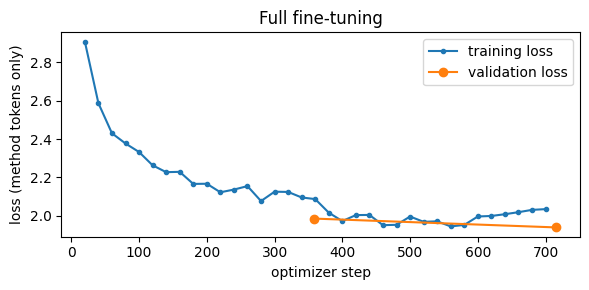

{'trainable': '124,439,808', 'minutes': 6.7, 'peak GB': 11.01} | final validation loss 1.939
Exercise 5 checks passed.


In [16]:
from accelerate.utils import extract_model_from_parallel


def collate(batch, pad_id=tokenizer.pad_token_id):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), pad_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train(model, args, train_data, eval_data, title, data_collator=collate):
    trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=eval_data,
                      data_collator=data_collator)
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    extract_model_from_parallel(model, keep_fp32_wrapper=False)   # remove the fp16 autocast wrapper: evaluate in fp32
    stats = {"trainable": count_trainable(model), "minutes": (time.perf_counter() - start) / 60,
             "peak GB": torch.cuda.max_memory_allocated() / GB if HAS_GPU else float("nan")}
    log = trainer.state.log_history
    tr = [(h["step"], h["loss"]) for h in log if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in log if "eval_loss" in h]
    plt.figure(figsize=(6, 3))
    if tr:
        plt.plot(*zip(*tr), marker=".", label="training loss")
    plt.plot(*zip(*ev), marker="o", label="validation loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss (method tokens only)"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()
    print({k: (f"{v:,}" if k == "trainable" else round(v, 2)) for k, v in stats.items()},
          "| final validation loss", round(ev[-1][1], 3))
    return stats, ev[-1][1]


transformers.set_seed(SEED)
full_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
full_stats, full_val_loss = train(full_model, make_args("full", FULL_LR), train_data, val_data, "Full fine-tuning")
assert full_stats["trainable"] == 124_439_808, "full fine-tuning trains every GPT-2 parameter"
print("Exercise 5 checks passed.")

**Question 5.** (a) Report the training time, peak memory, and final validation loss. (b) Use the bytes-per-parameter accounting from the [PEFT lecture](../../lectures/peft/peft_lora.ipynb) (weights, gradients, and two Adam moments in fp32: about 16 bytes per trainable parameter) to estimate the memory for GPT-2's weights and optimizer. Is the measured peak higher or lower, and what else uses memory during training? (c) The validation loss is computed on held-out dishes. Why is a falling validation loss still not enough to say the model writes better methods?

**Answer 5.** Full fine-tuning took **6.70 minutes**, peaked at **11.01 GB allocated GPU memory**, and finished with validation loss **1.939**. All 124,439,808 parameters were trainable. The simple weight/gradient/Adam estimate is 124,439,808 × 16 = 1,991,036,928 bytes, or **1.991 GB**. The measured peak is higher because training also stores activations, attention intermediates and temporary buffers; this notebook also keeps the original GPT-2 resident. Allocated memory is not the same as all memory reported by nvidia-smi. Validation loss measures method-token prediction on held-out dishes. It does not check whether an ingredient is supported, whether the cooking sequence works, or whether instructions are safe.

## Exercise 6 — LoRA (4 marks)

Now freeze GPT-2 and train only a LoRA adapter on the attention's input projection. In GPT-2 this is one layer per block, `c_attn`, which maps the 768-dimensional hidden state to the concatenated query, key, and value vectors (768 × 3 = 2,304 outputs). GPT-2 has 12 blocks.

**(a) Predict before you build.** With rank `r = 8`, how many trainable parameters does LoRA add? Recall that LoRA adds $A \in \mathbb{R}^{r \times d_\text{in}}$ and $B \in \mathbb{R}^{d_\text{out} \times r}$ to each adapted layer. Set `predicted_lora_params` to your number (as an arithmetic expression, not a copied total).

**(b) Configure.** Create `lora_config`: rank 8, `lora_alpha` 16, dropout 0.05, `target_modules=["c_attn"]`, task type causal LM, and `fan_in_fan_out=True`. (GPT-2 implements its linear layers as `Conv1D` modules, which store the weight transposed, as (in, out); this flag tells `peft` so. Without it, `peft` sets it for you and prints a warning.) Then wrap a **freshly loaded** GPT-2 with `get_peft_model`.

LoRA usually needs a higher learning rate than full fine-tuning, because only the small adapter moves and its update starts at zero (`B = 0`). We use `LORA_LR = 5e-4`, ten times `FULL_LR`; neither value was tuned for this lab.

In [18]:
import sys
# Bypasses the torchao incompatibility check in peft by hiding torchao from sys.modules
sys.modules["torchao"] = None

from peft import LoraConfig, get_peft_model
LORA_LR = 5e-4
transformers.set_seed(SEED)
lora_base = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
predicted_lora_params = 12 * 8 * (768 + 3 * 768)
lora_config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05,
    target_modules=["c_attn"], task_type="CAUSAL_LM", fan_in_fan_out=True)
lora_model = get_peft_model(lora_base, lora_config)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [19]:
lora_model.print_trainable_parameters()
assert count_trainable(lora_model) == predicted_lora_params, "your prediction does not match peft's count"
assert predicted_lora_params == 294_912, "check the shapes of A and B"
print("Exercise 6 configuration checks passed.")

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364
Exercise 6 configuration checks passed.


> **The next cell trains the LoRA adapter**, with the same data, epochs, batch size, and schedule as Exercise 5.

Epoch,Training Loss,Validation Loss
1,2.512465,2.354940
2,2.497726,2.313429


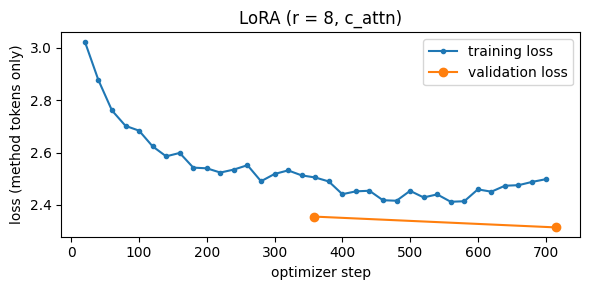

{'trainable': '294,912', 'minutes': 5.92, 'peak GB': 10.47} | final validation loss 2.313


,trainable,minutes,peak GB,val loss
full fine-tuning,124439808.0,6.697901,11.010565,1.939292
LoRA,294912.0,5.920469,10.473235,2.313429


In [20]:
lora_stats, lora_val_loss = train(lora_model, make_args("lora", LORA_LR), train_data, val_data, "LoRA (r = 8, c_attn)")
pd.DataFrame({"full fine-tuning": full_stats | {"val loss": full_val_loss},
              "LoRA": lora_stats | {"val loss": lora_val_loss}}).T

**Question 6.** (a) Show your calculation for `predicted_lora_params`, and give the adapter's size as a percentage of GPT-2's parameters. (b) Compare the two runs' training time and peak memory. LoRA trains about 0.24% of the parameters: why is the memory saving much smaller than that, and why is training not 400× faster? (c) Compare the two validation losses. Which run fits the recipes' wording better, and is that what you expected?

**Answer 6.** Each c_attn adapter adds r(d_in + d_out) = 8(768 + 2304) parameters. Across 12 blocks this gives **294,912**, which is **0.237% of the original GPT-2 count** (0.2364% when the adapter is included in the denominator, as PEFT prints).

| Run | Minutes | Peak allocated GB | Final validation loss |
| --- | ---: | ---: | ---: |
| Full fine-tuning | 6.70 | 11.01 | 1.939 |
| LoRA | 5.92 | 10.47 | 2.313 |

LoRA saved about **0.78 minutes (11.6%)** and **0.54 GB (4.9%)** in this notebook. These are shared-notebook peaks, not isolated per-model memory benchmarks: other model weights and tensors remain resident. LoRA still runs the frozen network and retains activations needed to learn the adapters, so a roughly 400-fold reduction in trainable parameters does not give a 400-fold speedup. Full fine-tuning fits the held-out recipe wording better here, which is plausible because all its weights can adapt; that capacity advantage is not proof of better cooking instructions.

## Exercise 7 — Compare the three models (4 marks)

Generate methods for the same validation recipes with both fine-tuned models, using the same helper and settings as the baseline.

In [21]:
start = time.perf_counter()
full_preds, full_stopped = generate_methods(full_model, tokenizer, eval_rows, add_bos=False)
lora_preds, lora_stopped = generate_methods(lora_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {2 * len(eval_rows)} methods in {time.perf_counter() - start:.0f} s")
evaluate("GPT-2 full FT", full_preds, full_stopped)
table = evaluate("GPT-2 LoRA", lora_preds, lora_stopped)
table

generated 80 methods in 51 s


,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,ingredients %,words,stopped %
GPT-2 original,3.7,30.8,6.9,17.4,56.3,219.0,65.0
GPT-2 full FT,10.1,46.2,17.5,29.3,75.8,164.2,100.0
GPT-2 LoRA,9.2,41.6,14.2,26.1,73.3,218.1,92.5


In [22]:
for i in (0, 1, 2):
    r = eval_rows[i]
    print(f"=================== {r['name']} ===================")
    print("INGREDIENTS:", "; ".join(r["ingredients"]))
    for name, preds in (("REFERENCE", refs), ("FULL FT", full_preds), ("LORA", lora_preds)):
        print(f"\n{name}: {preds[i][:700]}")
    print()

=================== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===================
INGREDIENTS: 2 tablespoons Ragi Flour (Finger Millet/ Nagli); 1/2 cup Water; 2 cups Milk; 1 teaspoon Jaggery; 2 teaspoons Almond Meal (Badam Powder); 1/2 teaspoon Cardamom Powder (Elaichi); 1/2 teaspoon Dry ginger powder; Saffron strands - a pinch - optional; 1 teaspoon Ghee - or butter

REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken. At this stage pour the milk and keep stirring well ensuring that there are no lumps in the Ragi Malt. Add jaggery, cardamom powder, saffron and almond powder to it. Cook in medium flame until the Ragi Malt/ Kanji becomes little thick like porridge. Once done, turn off the heat and serve. S

**Forgetting.** Fine-tuning on recipes can make a model worse at ordinary English, as in the lecture's Section 7. Measure it: complete `mean_loss(model, texts)`, the **token-weighted** mean cross-entropy of a model on a list of texts. For each text, tokenize it, call the model with `labels=input_ids` (the model shifts them), and weight its `.loss` by the number of predicted tokens, which is one less than the number of tokens. Use `torch.no_grad()` and `model.eval()`.

The four paragraphs below were written for this lab, about everyday topics with no cooking.

In [23]:
GENERAL_TEXTS = [
    "The train to Jaipur left the station twenty minutes late. Most passengers had already found their seats, "
    "and a few were reading newspapers while the countryside moved slowly past the windows.",
    "Rainwater that falls on the hills collects in small streams, which join to form rivers. Some of the water "
    "soaks into the ground and is stored in aquifers that supply wells during the dry season.",
    "The committee will meet on Monday to discuss the budget for the next financial year. Members are asked to "
    "read the report in advance and to send any questions to the secretary by Friday.",
    "In the final over, the batsman needed twelve runs to win. He hit the first ball for four, missed the next "
    "two, and then lifted a full toss over long-on for six.",
]

In [24]:
@torch.no_grad()
def mean_loss(model, texts):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    device = next(model.parameters()).device
    for text in texts:
        batch = tokenizer(text, return_tensors="pt").to(device)
        count = batch["input_ids"].shape[1] - 1
        if count > 0:
            loss = model(**batch, labels=batch["input_ids"]).loss
            total_loss += float(loss) * count
            total_tokens += count
    if not total_tokens:
        raise ValueError("Need at least one next-token prediction")
    return total_loss / total_tokens

In [25]:
forgetting = {name: mean_loss(m, GENERAL_TEXTS) for name, m in
              (("GPT-2 original", base_model), ("GPT-2 full FT", full_model), ("GPT-2 LoRA", lora_model))}
for name, loss in forgetting.items():
    print(f"{name:<16} loss on general English {loss:.3f}  (perplexity {math.exp(loss):.1f})")
with lora_model.disable_adapter():                    # the same object without its adapter = the original GPT-2
    assert abs(mean_loss(lora_model, GENERAL_TEXTS) - forgetting["GPT-2 original"]) < 1e-3
print("Exercise 7 checks passed.")

GPT-2 original   loss on general English 3.468  (perplexity 32.1)
GPT-2 full FT    loss on general English 4.051  (perplexity 57.4)
GPT-2 LoRA       loss on general English 3.565  (perplexity 35.3)
Exercise 7 checks passed.


**Question 7.** (a) Summarize the table: how did BLEU, ROUGE, ingredient coverage, length, and "stopped %" change from the original model to each fine-tuned model? (b) Most reference methods begin "To begin making the … Recipe," and end with a serving suggestion. How could this house style affect BLEU and ROUGE, and what does that tell you about what the scores reward? (c) For the three printed recipes, judge each fine-tuned method yourself: does it use the listed ingredients, are the steps in a sensible order, and does it invent an ingredient or an unsafe instruction? Does your judgment agree with the metrics? (d) Which model forgot more general English? Explain why in terms of what each method changes.

**Answer 7.** On the same 40 validation recipes:

| Model | BLEU | ROUGE-1 | ROUGE-2 | ROUGE-L | Ingredient coverage % | Mean words | Stopped % |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Original GPT-2 | 3.73 | 30.84 | 6.86 | 17.40 | 56.25 | 218.98 | 65.0 |
| Full fine-tuning | 10.15 | 46.16 | 17.50 | 29.31 | 75.82 | 164.15 | 100.0 |
| LoRA | 9.15 | 41.60 | 14.17 | 26.10 | 73.32 | 218.12 | 92.5 |

Both trained models improved overlap, ingredient-word coverage and stopping. Full fine-tuning scored higher on every listed quality proxy and generated shorter methods. The references averaged 234.2 words and 76.9% ingredient-word coverage, so 100% coverage is not a realistic reference ceiling. Coverage measures word mentions, not correct use. The repeated opening “To begin making…” and serving suggestions also raise n-gram overlap; learning this house style is easier than learning a valid procedure.

**Reading the three printed comparisons:**

- **Sweet Ragi Malt:** full fine-tuning mentions many listed ingredients, but washes/soaks flour and grinds a paste instead of roasting and cooking the porridge; it adds yogurt, salt and several ginger forms. LoRA even says to wash the flour and milk, adds yogurt and salt, and does not clearly use the listed jaggery and almond meal. Neither is a reliable method.
- **Urulaikizhangu Podi Poriyal:** both name potatoes, sesame oil, chillies and dal, but refer to cooked potatoes without a clear boiling step and to masala without a clear preparation. Full fine-tuning is repetitive; LoRA is much longer, repeats heating/adding steps and suggests an unrelated prawn accompaniment. Ingredient mentions do not fix the missing sequence.
- **Spicy Baby Potatoes:** full fine-tuning invents spinach and corn and does not clearly boil the potatoes before short cooking steps. LoRA refers to cooked potatoes without explaining that preparation, then adds chickpeas, milk, spinach and tomatoes. Both stray from the listed ingredients and neither establishes doneness reliably.

This reading broadly supports the full model's higher aggregate scores and better concision, but not a claim that its recipes are correct or safe. These are qualitative flags from the supplied text, not a practical food-safety assessment.

General-English loss/perplexity changed from **3.468 / 32.1** originally to **4.051 / 57.4** for full fine-tuning and **3.565 / 35.3** for LoRA. Full fine-tuning forgot more on these four passages (loss increase 0.583 versus 0.097), consistent with modifying every base weight rather than a constrained low-rank update. Four passages are a narrow probe, not a general language benchmark. The adapter-disable check passed.

## Exercise 8 — Save and merge the adapter (1 mark)

Only the adapter is saved: a user who has GPT-2 needs nothing else. For deployment, the adapter can be **merged** into the weights ($W \leftarrow W + \frac{\alpha}{r} BA$), which removes LoRA's extra computation. Merging should not change the outputs, up to floating-point rounding.

In [26]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
lora_model.save_pretrained(ADAPTER_DIR)
adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.iterdir()) / 1e6
print(f"adapter on disk: {adapter_mb:.2f} MB | GPT-2 in fp32: {124_439_808 * 4 / 1e6:.0f} MB")

probe = tokenizer(format_prompt(eval_rows[0]), return_tensors="pt").to(DEVICE)
with torch.no_grad():
    before = lora_model(**probe).logits
    merged = lora_model.merge_and_unload()           # modifies the model in place: run this cell last
    after = merged(**probe).logits
print(f"largest logit change after merging: {(before - after).abs().max().item():.2e}")
assert (before - after).abs().max().item() < 1e-2, "merging should change the logits only by rounding"
assert sum(p.numel() for p in merged.parameters()) == 124_439_808
assert not any("lora" in n for n, _ in merged.named_parameters())

adapter on disk: 1.19 MB | GPT-2 in fp32: 498 MB
largest logit change after merging: 1.79e-04


**Question 8.** (a) Explain the adapter's size from its parameter count. (b) Why is the largest logit change not exactly zero? (c) A team wants five recipe styles (by region) on one server. Would you merge five adapters into five model copies, or keep one base model and swap adapters? Give one reason for each choice.

**Answer 8.** The adapter matrices contain 294,912 parameters. At fp32 they occupy **1,179,648 bytes (1.18 MB)** before configuration and file overhead, matching the measured **1.19 MB** directory. The original GPT-2 fp32 weights alone occupy about **498 MB**. Merging changes multiplication/addition order and rounds floating-point values, so the maximum logit difference was **1.79 × 10^-4**, rather than exactly zero; this passed the 10^-2 tolerance.

For five regional styles, I would normally keep one base and swap separate adapters: storage is much smaller and the styles can be updated independently. Five merged copies remove adapter computations and switching overhead and can simplify concurrent serving, but duplicate the base weights. I would benchmark throughput and verify generation after merging before choosing the deployment arrangement.

## Reflection and deliverables (1 mark)

Submit this notebook **with outputs**, your answers to Questions 1–8, and a short paragraph (about 150 words):

*The cooking app has a GPU budget for one fine-tuned GPT-2. Would you choose full fine-tuning or LoRA? Base your recommendation on the evidence you collected (the metrics table, your reading of the outputs, forgetting, time, memory, storage), say what that evidence does not show, and name the next experiment you would run.*

**Responsible use.**

- **Food safety.** A fluent method can still be wrong about cooking times, temperatures, or ingredients (raw kidney beans, undercooked meat, allergens not in the ingredient list). Generated recipes need human review before anyone cooks from them, and BLEU/ROUGE do not measure safety.
- **Licensing and attribution.** The dataset is CC BY 4.0, which requires attribution to its author. The recipe texts themselves were scraped from Archana's Kitchen, whose own terms apply to that content; use the data for study, and check the terms before publishing a model or its outputs. GPT-2 is MIT-licensed.
- **Memorization.** A fine-tuned model can reproduce training recipes word for word. Before publishing outputs as "new" recipes, check them against the training data.
- **Representation.** The site covers some regions far more than others (see the cuisine counts). A model fine-tuned on it will write North and South Indian dishes more fluently than, say, North-Eastern ones.

**Optional extensions (not graded).** (1) Train LoRA with `r` = 2 and 32 and plot validation loss against `r` (lecture, Section 6). (2) Add `c_proj` and the MLP layers (`c_fc`, `mlp.c_proj`) to `target_modules` and compare. (3) Recompute BLEU/ROUGE without the first sentence of each method (Question 7b).

## Final reflection

For an app with enough GPU memory for either run, I would choose full fine-tuning for this recipe-drafting task. It achieved BLEU 10.15 and ROUGE-L 29.31, compared with 9.15 and 26.10 for LoRA, and stopped naturally on all 40 examples. Its methods were shorter and generally less repetitive. The extra measured training cost was only about 0.78 minutes and 0.54 GB in this shared notebook. However, LoRA's 1.19 MB adapter is much easier to store and swap, and its general-English loss increased much less. Those advantages would matter more for several regional styles. Neither approach is ready to produce unchecked cooking instructions: both invented ingredients and omitted preparation steps. These results cover one seed, 40 recipes and four general-English passages; overlap metrics and ingredient mentions do not establish correctness or safety. Next I would repeat the comparison with additional seeds and a blinded, ingredient-grounded human evaluation, also removing the standard opening sentence when calculating overlap scores.

## Optional extension — LoRA on Llama-3.2-1B (not graded)

GPT-2 dates from 2019. Does a modern model of about ten times its size write better methods after the same kind of LoRA fine-tuning? Llama-3.2-1B uses the components from Module 2's [modern LLM](../../../module2/transformers/attention_mechanisms.ipynb) unit: rotary position embeddings, grouped-query attention (32 query heads but only 8 key/value heads), and a 128,256-token vocabulary. We use the **base** model, not the Instruct version, so that it gets the same plain-text prompt as GPT-2.

**Access.** The model is gated. Once per account:

1. Sign in to Hugging Face, open [meta-llama/Llama-3.2-1B](https://huggingface.co/meta-llama/Llama-3.2-1B), read the Llama 3.2 Community License and Acceptable Use Policy, and request access. Approval is usually quick, but not instant.
2. Create an access token with read permission (Settings → Access Tokens).
3. In Kaggle: Add-ons → Secrets → add a secret named `HF_TOKEN` with the token, and attach it to this notebook. Elsewhere, set the environment variable `HF_TOKEN`. **Never paste the token into a cell.**

**Compute.** The model is about 2.5 GB in 16-bit and is trained in 16-bit with LoRA (no quantization). To keep the run short, it trains for one epoch on `LLAMA_N_TRAIN` recipes and is evaluated on the first `LLAMA_N_EVAL` evaluation recipes. Time and memory have not been measured; expect roughly 10–20 minutes of training on a T4. Set `RUN_LLAMA = True` to run the section; the cell below first frees the GPT-2 models.

In [27]:
RUN_LLAMA = False
LLAMA_CKPT = "meta-llama/Llama-3.2-1B"
LLAMA_N_TRAIN, LLAMA_N_EVAL = 1000, 20


def hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")


if RUN_LLAMA:
    assert HAS_GPU, "the Llama extension needs a GPU"
    import gc
    del base_model, full_model, lora_model, lora_base, merged
    gc.collect(); torch.cuda.empty_cache()
    HF_TOKEN = hf_token()
    assert HF_TOKEN, "no Hugging Face token found: see 'Access' above"
    llama_tok = AutoTokenizer.from_pretrained(LLAMA_CKPT, token=HF_TOKEN)
    if llama_tok.pad_token is None:
        llama_tok.pad_token = llama_tok.eos_token
    print("BOS", repr(llama_tok.bos_token), llama_tok.bos_token_id, "| EOS", repr(llama_tok.eos_token), llama_tok.eos_token_id)
    for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
        print(f"{word:>8} -> {llama_tok.tokenize(' ' + word)}")
    sample = splits["train"][:200]
    n_gpt2 = sum(len(build_example(r, tokenizer, False)["input_ids"]) for r in sample)
    n_llama = sum(len(build_example(r, llama_tok, True)["input_ids"]) for r in sample)
    print(f"tokens for 200 training recipes: GPT-2 {n_gpt2:,} | Llama {n_llama:,} ({n_llama / n_gpt2:.2f}x)")

`build_example` is reused with `add_bos=True`: Llama was trained with `<|begin_of_text|>` at the start of every document, and we add it **explicitly** rather than relying on the tokenizer's default, which has changed between library versions. The check below prints the first and last tokens, as you should always do with a new tokenizer.

In [28]:
if RUN_LLAMA:
    llama_train = make_dataset(splits["train"][:LLAMA_N_TRAIN], llama_tok, add_bos=True)
    e = llama_train[0]
    print("first tokens:", llama_tok.convert_ids_to_tokens(e["input_ids"][:4]),
          "| last:", llama_tok.convert_ids_to_tokens(e["input_ids"][-2:]))
    assert e["input_ids"][0] == llama_tok.bos_token_id and e["input_ids"][1] != llama_tok.bos_token_id
    assert e["input_ids"][-1] == llama_tok.eos_token_id
    llama_rows = eval_rows[:LLAMA_N_EVAL]

    transformers.set_seed(SEED)
    llama = AutoModelForCausalLM.from_pretrained(LLAMA_CKPT, dtype=torch.float16, token=HF_TOKEN, device_map={"": 0})
    print(f"Llama parameters: {sum(p.numel() for p in llama.parameters()):,} | "
          f"GPU memory after loading: {torch.cuda.memory_allocated() / GB:.2f} GB")
    print(llama.model.layers[0].self_attn)

**Extension task A.** The printed attention block shows the projection shapes. Predict the number of LoRA parameters for rank 16 on `q_proj`, `k_proj`, `v_proj`, and `o_proj` in all 16 layers, then complete `llama_lora_config()` (rank 16, `lora_alpha` 32, dropout 0.05, those four target modules, causal LM; no `fan_in_fan_out`, since Llama uses ordinary `nn.Linear` layers).

In [29]:
def llama_lora_config():
    return LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM")
# Llama 3.2 1B: hidden 2048, 32 query heads, 8 KV heads, head width 64.
LLAMA_PREDICTED = 16 * 16 * ((2048 + 2048) + 2 * (2048 + 512) + (2048 + 2048))

The next cell generates with the original Llama, attaches the adapter, and trains. Gradient checkpointing (recomputing activations during the backward pass) keeps memory down; the large vocabulary makes the logits expensive, so the batch is 4 with 2 accumulation steps (an effective batch of 8, as for GPT-2).

In [30]:
if RUN_LLAMA:
    llama_base_preds, llama_base_stopped = generate_methods(llama, llama_tok, llama_rows, add_bos=True)
    llama_lora = get_peft_model(llama, llama_lora_config())
    llama_lora.print_trainable_parameters()
    assert count_trainable(llama_lora) == LLAMA_PREDICTED, "prediction and peft disagree"
    llama_args = TrainingArguments(
        output_dir=str(OUT / "llama_lora"), per_device_train_batch_size=4, gradient_accumulation_steps=2,
        num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10, fp16=True,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        eval_strategy="epoch", logging_steps=10, save_strategy="no", report_to="none",
        remove_unused_columns=False, seed=SEED)
    llama_val = make_dataset(splits["val"][:100], llama_tok, add_bos=True)
    llama_stats, llama_val_loss = train(llama_lora, llama_args, llama_train, llama_val, "Llama-3.2-1B, LoRA r = 16",
                                        data_collator=lambda b: collate(b, pad_id=llama_tok.pad_token_id))
    llama_lora_preds, llama_lora_stopped = generate_methods(llama_lora, llama_tok, llama_rows, add_bos=True)

The comparison uses the same `LLAMA_N_EVAL` recipes for every model. `sacrebleu` and `rouge_score` tokenize the text themselves, so the scores of models with different tokenizers are comparable.

In [31]:
if RUN_LLAMA:
    from IPython.display import display
    results.clear()
    k = LLAMA_N_EVAL
    for name, preds, stopped in (("GPT-2 original", base_preds[:k], base_stopped[:k]),
                                 ("GPT-2 full FT", full_preds[:k], full_stopped[:k]),
                                 ("GPT-2 LoRA", lora_preds[:k], lora_stopped[:k]),
                                 ("Llama original", llama_base_preds, llama_base_stopped)):
        evaluate(name, preds, stopped, llama_rows)
    display(evaluate("Llama LoRA", llama_lora_preds, llama_lora_stopped, llama_rows))
    for i in (0, 1):
        print(f"=== {llama_rows[i]['name']} ===\nLLAMA LoRA: {llama_lora_preds[i][:700]}\nGPT-2 LoRA: {lora_preds[i][:700]}\n")

**Extension questions.** (A) Explain your prediction of the LoRA parameter count. Why are the `k_proj` and `v_proj` adapters smaller than the `q_proj` adapter? (B) Llama's vocabulary is about 2.5 times larger than GPT-2's (128,256 vs. 50,257 tokens). Compare the printed token counts and the splits of the Indian words: did the larger vocabulary help much on these recipes? Suggest why. Does the model's tokenizer change BLEU or ROUGE directly? (C) Compare Llama LoRA with GPT-2 LoRA and GPT-2 full fine-tuning. List at least three ways in which this comparison is **not** controlled (think about training data, epochs, model size, rank, evaluation size), and say what you would change to make it fair.

**Extension answer.** Rank 16 adds 3,407,872 parameters across q, k, v and o projections in 16 layers. Llama uses grouped-query attention, so key/value outputs have width 512, while query/output projections use width 2048. The optional gated experiment uses its own 1,000-example training subset and 20 validation recipes. Its measured table, runtime and memory are needed before comparing checkpoints; it does not isolate architecture alone because the data budget differs. It remains optional and is disabled by default.

## References

1. Jain, K. (2020). [6000+ Indian Food Recipes Dataset](https://data.mendeley.com/datasets/xsphgmmh7b/1). Mendeley Data, V1, doi:10.17632/xsphgmmh7b.1. CC BY 4.0. Recipes from [Archana's Kitchen](https://www.archanaskitchen.com/).
2. Radford, Wu, Child, Luan, Amodei & Sutskever (2019). [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf). OpenAI · [GPT-2 on the Hub](https://huggingface.co/openai-community/gpt2).
3. Hu et al. (2021). [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685).
4. Papineni, Roukos, Ward & Zhu (2002). [BLEU: a Method for Automatic Evaluation of Machine Translation](https://aclanthology.org/P02-1040/). ACL.
5. Lin (2004). [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/) · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
6. Post (2018). [A Call for Clarity in Reporting BLEU Scores](https://aclanthology.org/W18-6319/). WMT · [`sacrebleu`](https://github.com/mjpost/sacrebleu).
7. Llama Team, AI @ Meta (2024). [The Llama 3 Herd of Models](https://arxiv.org/abs/2407.21783) · [Llama-3.2-1B model card](https://huggingface.co/meta-llama/Llama-3.2-1B).
8. Hugging Face documentation: [PEFT](https://huggingface.co/docs/peft) · [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer) · [text generation strategies](https://huggingface.co/docs/transformers/generation_strategies).

In [32]:
import json
OUT.mkdir(parents=True, exist_ok=True)
pd.DataFrame(results).T.to_csv(OUT / "recipe_metrics.csv")
pd.DataFrame({"dish": [r["name"] for r in eval_rows], "reference": refs,
              "base": base_preds, "full": full_preds, "lora": lora_preds}).to_csv(OUT / "recipe_predictions.csv", index=False)
(OUT / "run_summary.json").write_text(json.dumps({"seed": SEED, "train_limit": TRAIN_LIMIT,
    "epochs": EPOCHS, "batch": BATCH, "full": full_stats, "lora": lora_stats,
    "general_loss": forgetting}, indent=2, allow_nan=False) if HAS_GPU else json.dumps({
    "seed": SEED, "gpu": False, "full_minutes": full_stats["minutes"],
    "lora_minutes": lora_stats["minutes"], "general_loss": forgetting}, indent=2))
print("Saved measured metrics and predictions in", OUT)

Saved measured metrics and predictions in recipe_lab_outputs
